# Kaplan-Meier — Empirical vs Model-Predicted Survival

For each subtask execution stage (download, execution, upload), this notebook plots:

1. **Empirical KM curves** — Kaplan-Meier survival estimated per stratum directly from the observed data.
2. **Model-predicted curves** — average survival curve per stratum, computed by replaying each task's *actual observed covariate trajectory* through the fitted discrete-time hazard model (`TaskCompletionModel` via `VectorPLRSimulator`), then averaging the resulting per-task survival curves within each stratum.

In [1]:
import os
import sys
root = os.path.abspath("..")
sys.path.append(root)

import shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scienceplots
from lifelines import KaplanMeierFitter

from config import Config
from utils.task_completion_model import TaskCompletionModel
from utils.vector_plr_simulator import VectorPLRSimulator

if shutil.which("latex"):
    plt.style.use(["science", "ieee"])
else:
    plt.style.use(["science", "ieee", "no-latex"])

config = Config()
figures_dir = os.path.join(config.resource_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

## Configuration

In [2]:
CONF_COLUMNS = ["conf_trial", "conf_bandwidth_in",
                "conf_bandwidth_out", "conf_task_count", "conf_model_name"]  # uniquely identifies one task run
STRATIFICATION_COLS = ["conf_model_name"]

STAGES = {
    "download": {
        "data_path": "../resources/data/y_resource_consumption_downloading_augmented.csv",
        "model_path": "../resources/models/task_completion_download_model.json",
    },
    "execution": {
        "data_path": "../resources/data/y_resource_consumption_executing_augmented.csv",
        "model_path": "../resources/models/task_completion_execution_model.json",
    },
    "upload": {
        "data_path": "../resources/data/y_resource_consumption_uploading_augmented.csv",
        "model_path": "../resources/models/task_completion_upload_model.json",
    },
}

# Colors/linestyles come from the scienceplots "ieee" style's own cycle (axes.prop_cycle),
# not an invented palette. That cycle only has 4 color<->linestyle pairs, so we add a
# marker dimension to reach 12 unique combos: no two strata share both a linestyle and
# a marker, keeping curves distinguishable by shape alone for colorblind readers / grayscale print.
_ieee_cycle = plt.rcParams["axes.prop_cycle"].by_key()
_IEEE_COLORS = _ieee_cycle["color"]
_IEEE_LINESTYLES = _ieee_cycle["linestyle"]
_MARKERS = ["o", "s", "^"]
# Paired 1:1 with _MARKERS: within a (color, linestyle) group, the 3 strata that only
# differ by marker also get a distinct linewidth, since marker shape alone is a weak
# cue once curves overlap tightly (markers are sparse and often hidden).
_LINEWIDTHS = [0.8, 1.2, 1.6]


def stratum_styles(strata_labels):
    """Map each stratum label to a (color, linestyle, marker, linewidth) tuple using
    the IEEE style's own color/linestyle cycle, extended with markers and linewidths;
    no two strata share both a linestyle and a marker."""
    n_base = len(_IEEE_COLORS)
    n_combos = n_base * len(_MARKERS)
    if len(strata_labels) > n_combos:
        raise ValueError(f"only {n_combos} distinguishable styles available, got {len(strata_labels)} strata")
    styles = {}
    for i, label in enumerate(strata_labels):
        color = _IEEE_COLORS[i % n_base]
        linestyle = _IEEE_LINESTYLES[i % n_base]
        group = (i // n_base) % len(_MARKERS)
        marker = _MARKERS[group]
        linewidth = _LINEWIDTHS[group]
        styles[label] = (color, linestyle, marker, linewidth)
    return styles

## Helper functions

- `empirical_km_curves` — one row per task (collapsed from the person-second data), fit a `KaplanMeierFitter` per stratum.
- `model_predicted_survival_curves` — for every task, replay its *real* per-second covariate trajectory through the fitted model to get a predicted survival probability at each of its time steps, then average the resulting hazards across tasks within a stratum and convert back to a survival curve.

In [3]:
def empirical_km_curves(df, conf_columns, stratification_columns):
    task_df = df.groupby(conf_columns).size().reset_index(name="duration")
    task_df["event"] = 1  # no censoring — every task completes

    if len(stratification_columns) == 1:
        task_df["_stratum_label"] = task_df[stratification_columns[0]].astype(str)
    else:
        task_df["_stratum_label"] = task_df[stratification_columns].astype(str).agg(" | ".join, axis=1)

    strata_labels = sorted(task_df["_stratum_label"].unique())

    kmfs = {}
    for label in strata_labels:
        mask = task_df["_stratum_label"] == label
        kmf = KaplanMeierFitter(label=f"{label}")
        kmf.fit(task_df.loc[mask, "duration"], event_observed=task_df.loc[mask, "event"])
        kmfs[label] = kmf

    return task_df, strata_labels, kmfs

In [4]:
def model_predicted_survival_curves(df, task_df, model, conf_columns):
    simulator = VectorPLRSimulator([model])
    strata_to_idx = {s: i for i, s in enumerate(model.model_strata)}

    pp_df = df.copy()
    pp_df["t"] = pp_df.groupby(conf_columns).cumcount() + 1
    pp_df_grouped = {key: grp.sort_values("t") for key, grp in pp_df.groupby(conf_columns)}
    max_t = int(pp_df["t"].max())
    t_grid = np.arange(1, max_t + 1)

    strata_labels = sorted(task_df["_stratum_label"].unique())
    curves = {}

    for label in strata_labels:
        task_keys = task_df.loc[task_df["_stratum_label"] == label, conf_columns]
        n_tasks = len(task_keys)
        hazard_matrix = np.full((n_tasks, max_t), np.nan)

        for i, (_, row) in enumerate(task_keys.iterrows()):
            key = tuple(row[col] for col in conf_columns)
            key = key[0] if len(key) == 1 else key
            task_rows = pp_df_grouped[key]
            n_rows = len(task_rows)

            # float32 to match model_params dtype (TaskCompletionModel.load defaults to float32)
            const_vals = task_rows[model.constant_feature_columns].values.astype(np.float32)
            var_vals = task_rows[model.variable_feature_columns].values.astype(np.float32)
            const_t = torch.tensor(const_vals.T, dtype=torch.float32)
            var_t = torch.tensor(var_vals.T, dtype=torch.float32)
            time_t = torch.tensor(task_rows["t"].values, dtype=torch.float32)

            model_idx_t = torch.zeros(n_rows, dtype=torch.long)
            strata_idx_t = torch.full((n_rows,), strata_to_idx[label], dtype=torch.long)
            mask_t = torch.ones(n_rows, dtype=torch.bool)

            with torch.no_grad():
                survival_per_interval = simulator.simulate(
                    const_t, var_t, time_t, model_idx_t, strata_idx_t, mask_t)
            hazard_matrix[i, :n_rows] = (1.0 - survival_per_interval).numpy()

        n_at_risk = np.sum(~np.isnan(hazard_matrix), axis=0)
        last_t = int(np.max(np.where(n_at_risk > 0)))

        mean_hazard = np.nanmean(hazard_matrix[:, :last_t + 1], axis=0)
        mean_sv = np.concatenate([[1.0], np.cumprod(1.0 - mean_hazard)])
        t = np.concatenate([[0], t_grid[:last_t + 1]])

        curves[label] = (t, mean_sv, n_tasks)

    return curves

In [5]:
FIG_W = 8.5 / 2.54
FIG_H = 5.0 / 2.54

# Font sizes: same as available_resources.ipynb
_FONT_SCALE  = FIG_W / 4.0
LABEL_FONTSIZE = 12 * _FONT_SCALE
XTICK_FONTSIZE = 14 * _FONT_SCALE
YTICK_FONTSIZE = 10 * _FONT_SCALE


def plot_empirical_km(strata_labels, kmfs, description, filename):
    styles = stratum_styles(strata_labels)
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
    for label in strata_labels:
        color, linestyle, marker, linewidth = styles[label]
        sf = kmfs[label].survival_function_
        ax.step(sf.index.values, sf.iloc[:, 0].values, where="post",
                color=color, linestyle=linestyle, linewidth=linewidth,
                marker=marker, markersize=3.5, markevery=0.08, markeredgewidth=0.6,
                label=kmfs[label]._label)
    ax.set_xlabel("Time (s)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Survival probability", fontsize=LABEL_FONTSIZE)
    ax.tick_params(axis="x", labelsize=XTICK_FONTSIZE)
    ax.tick_params(axis="y", labelsize=YTICK_FONTSIZE)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xscale("log")
    ax.legend(fontsize=5.5, loc="upper right", ncol=2, columnspacing=0.8, handletextpad=0.4)
    plt.tight_layout()

    print(description)
    plt.savefig(os.path.join(figures_dir, filename), bbox_inches="tight")
    plt.show()


def plot_model_curves(strata_labels, curves, description, filename, show_ylabel=False):
    styles = stratum_styles(strata_labels)
    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
    for label in strata_labels:
        color, linestyle, marker, linewidth = styles[label]
        t, mean_sv, n_tasks = curves[label]
        ax.step(t, mean_sv, where="post", color=color, linestyle=linestyle, linewidth=linewidth,
                marker=marker, markersize=3.5, markevery=0.08, markeredgewidth=0.6,
                label=f"{label}")
    ax.set_xlabel("Time (s)", fontsize=LABEL_FONTSIZE)
    if show_ylabel:
        ax.set_ylabel("Survival probability", fontsize=LABEL_FONTSIZE)
    ax.tick_params(axis="x", labelsize=XTICK_FONTSIZE)
    ax.tick_params(axis="y", labelsize=YTICK_FONTSIZE)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xscale("log")
    ax.legend(fontsize=5.5, loc="upper right", ncol=2, columnspacing=0.8, handletextpad=0.4)
    plt.tight_layout()

    print(description)
    plt.savefig(os.path.join(figures_dir, filename), bbox_inches="tight")
    plt.show()

## Run per stage

Download — Empirical KM survival


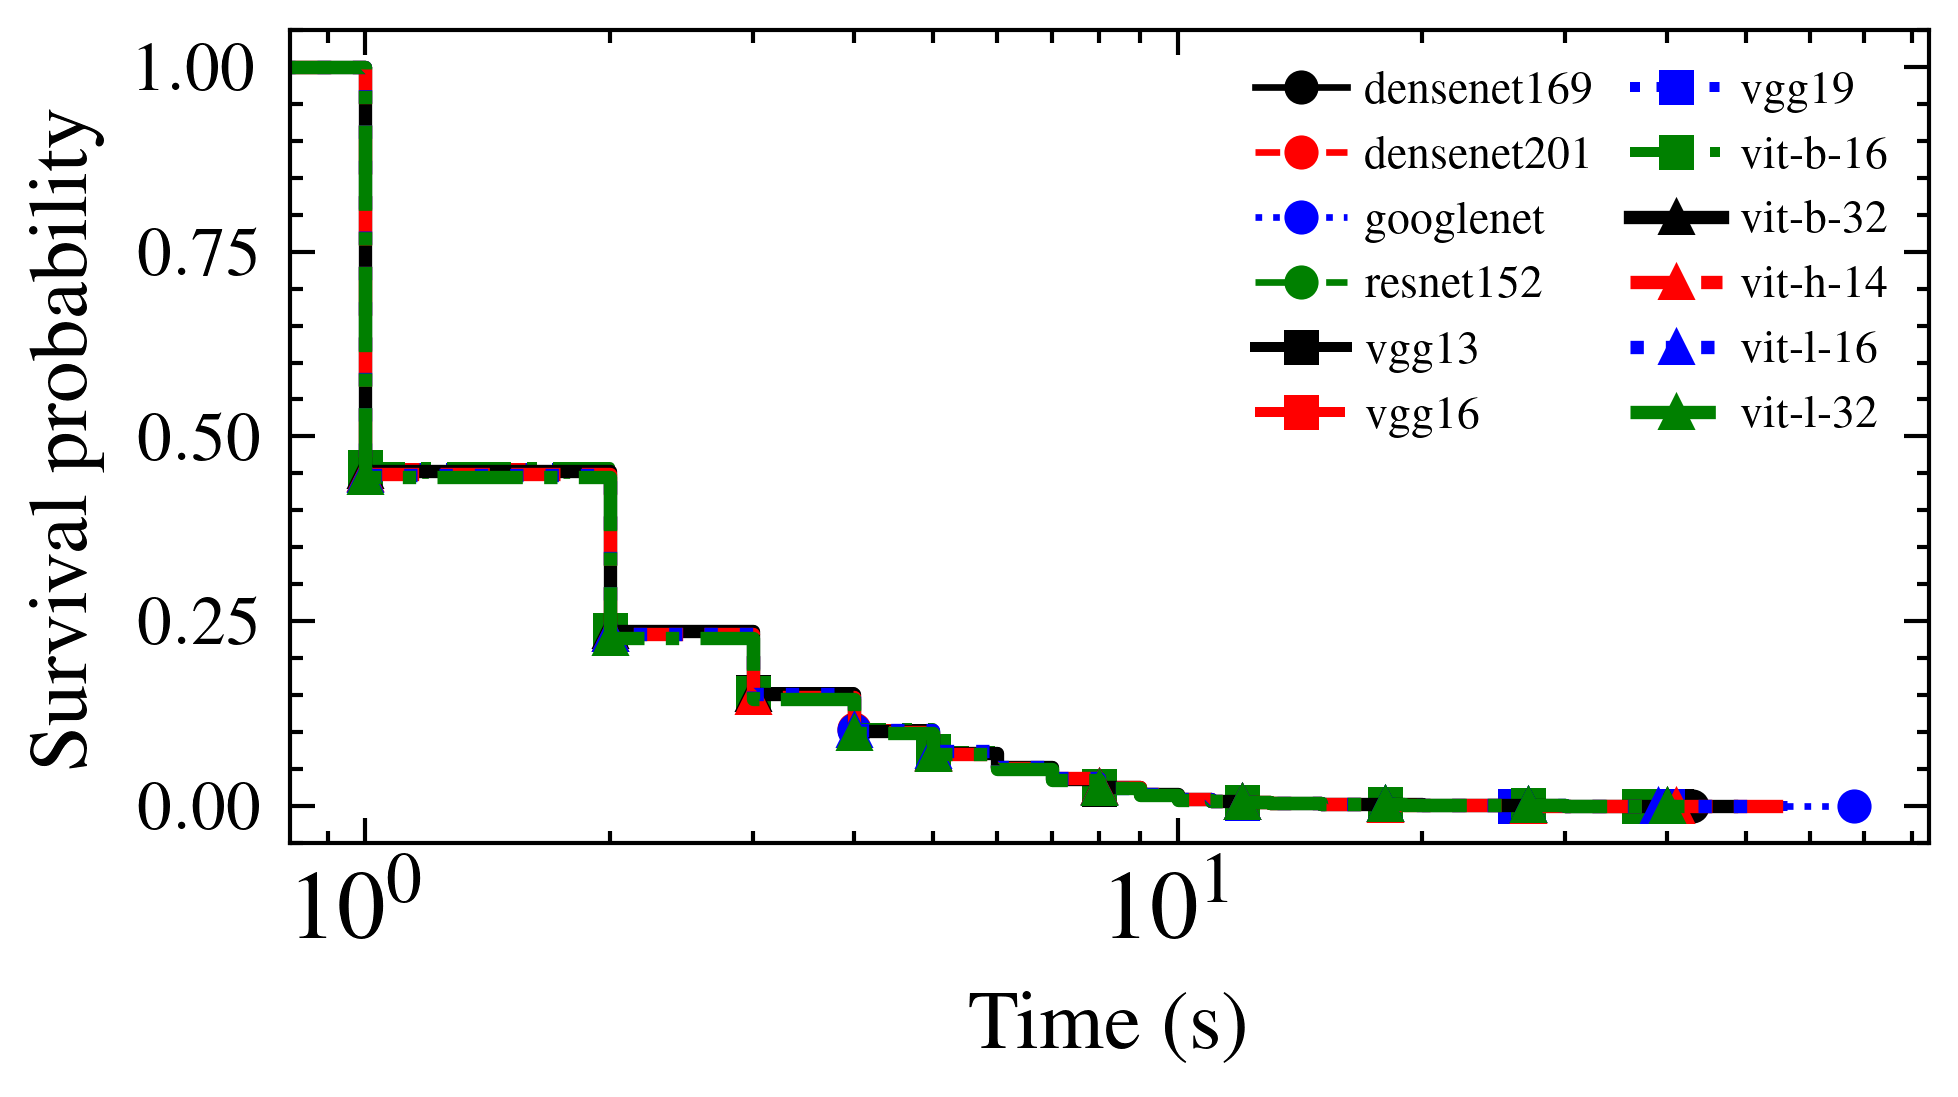

Download — Model-predicted survival


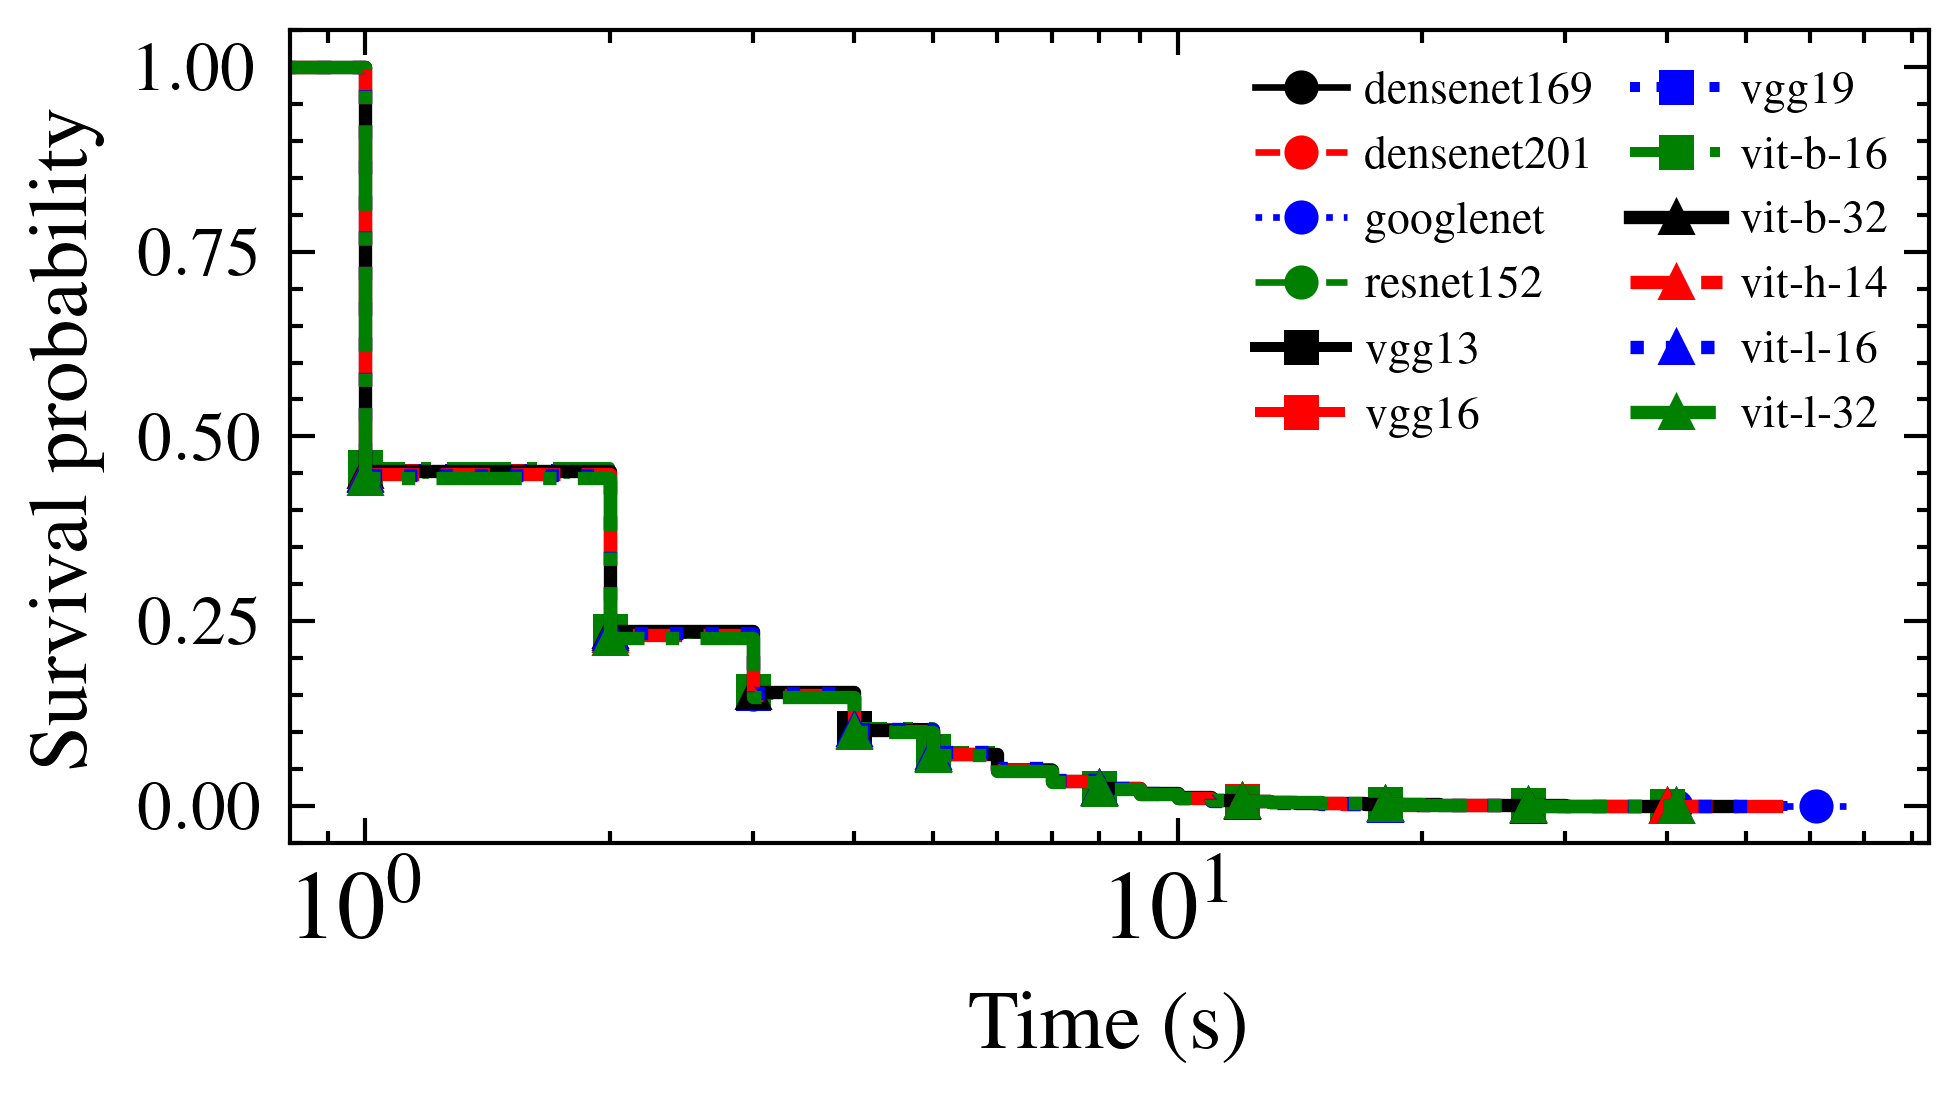

Execution — Empirical KM survival


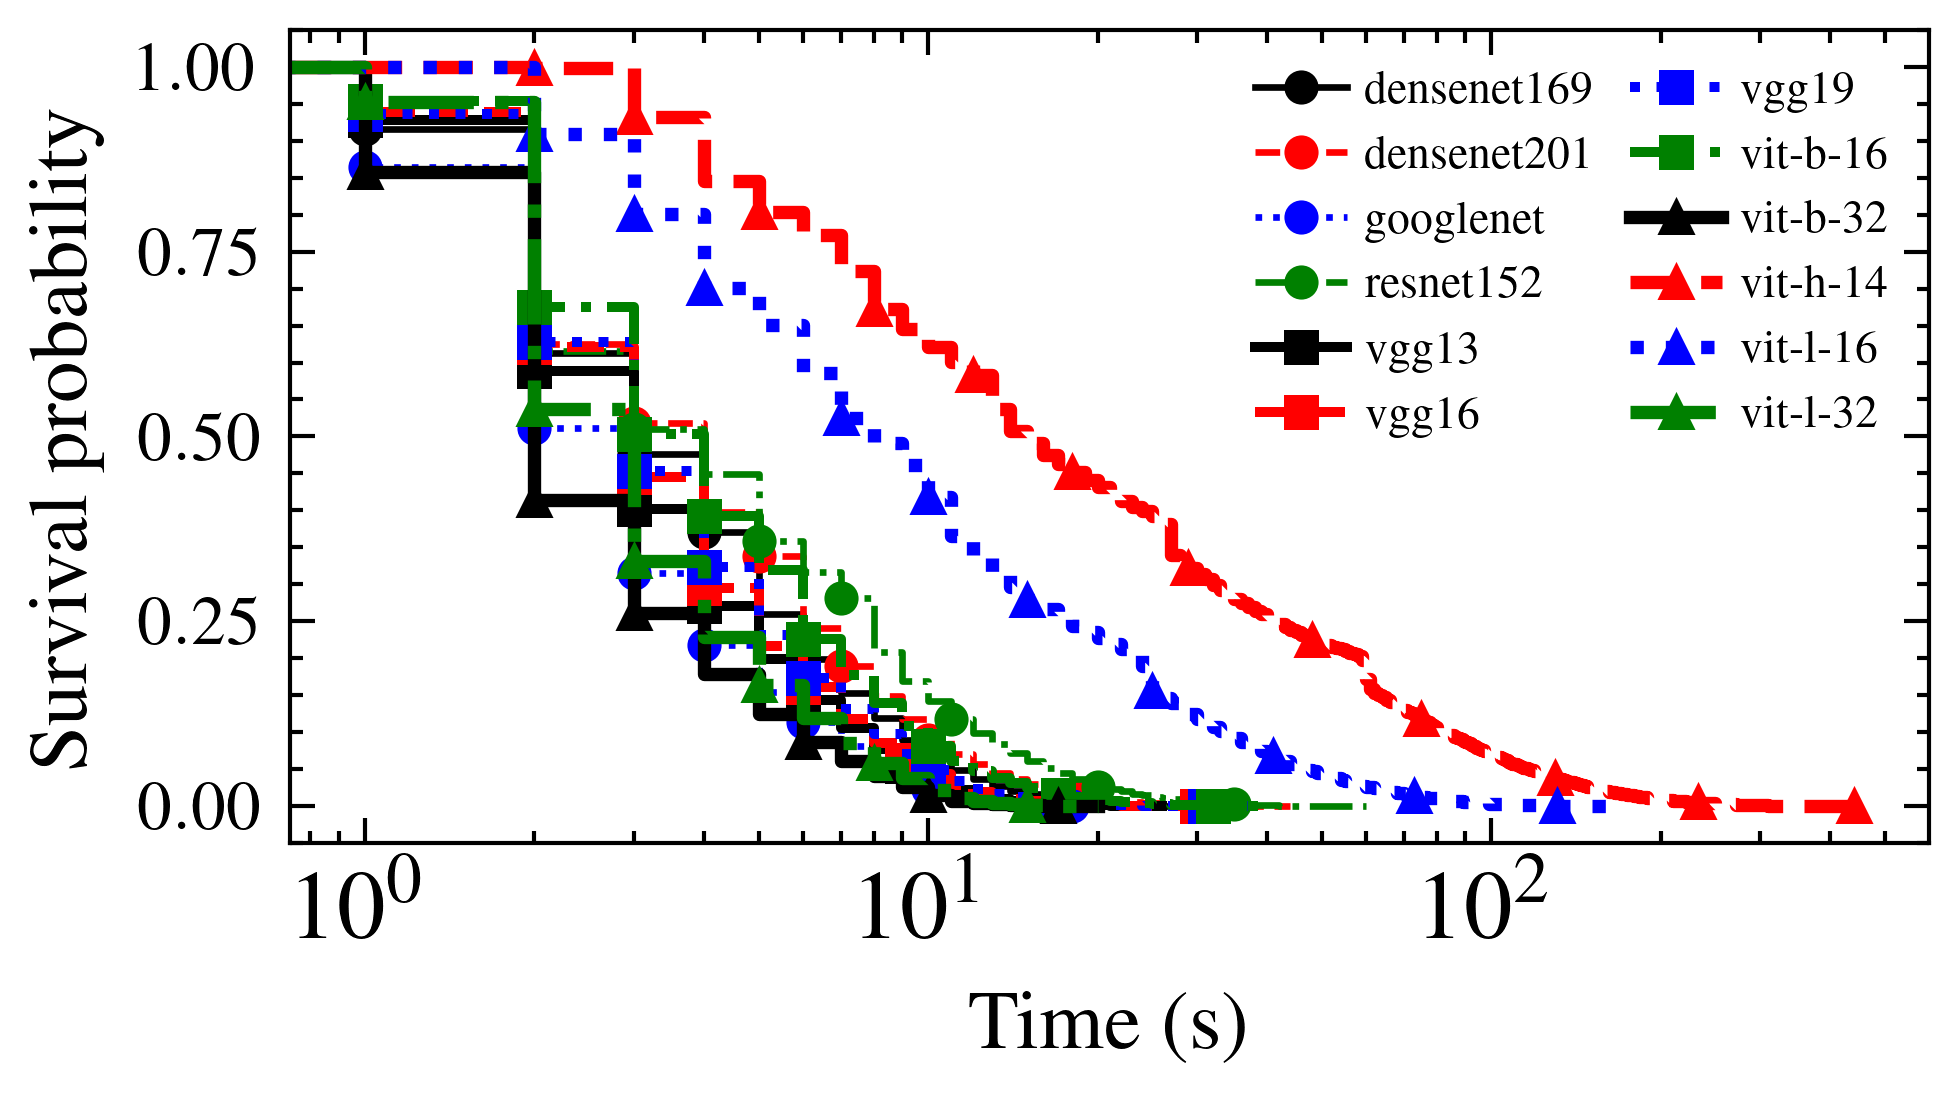

Execution — Model-predicted survival


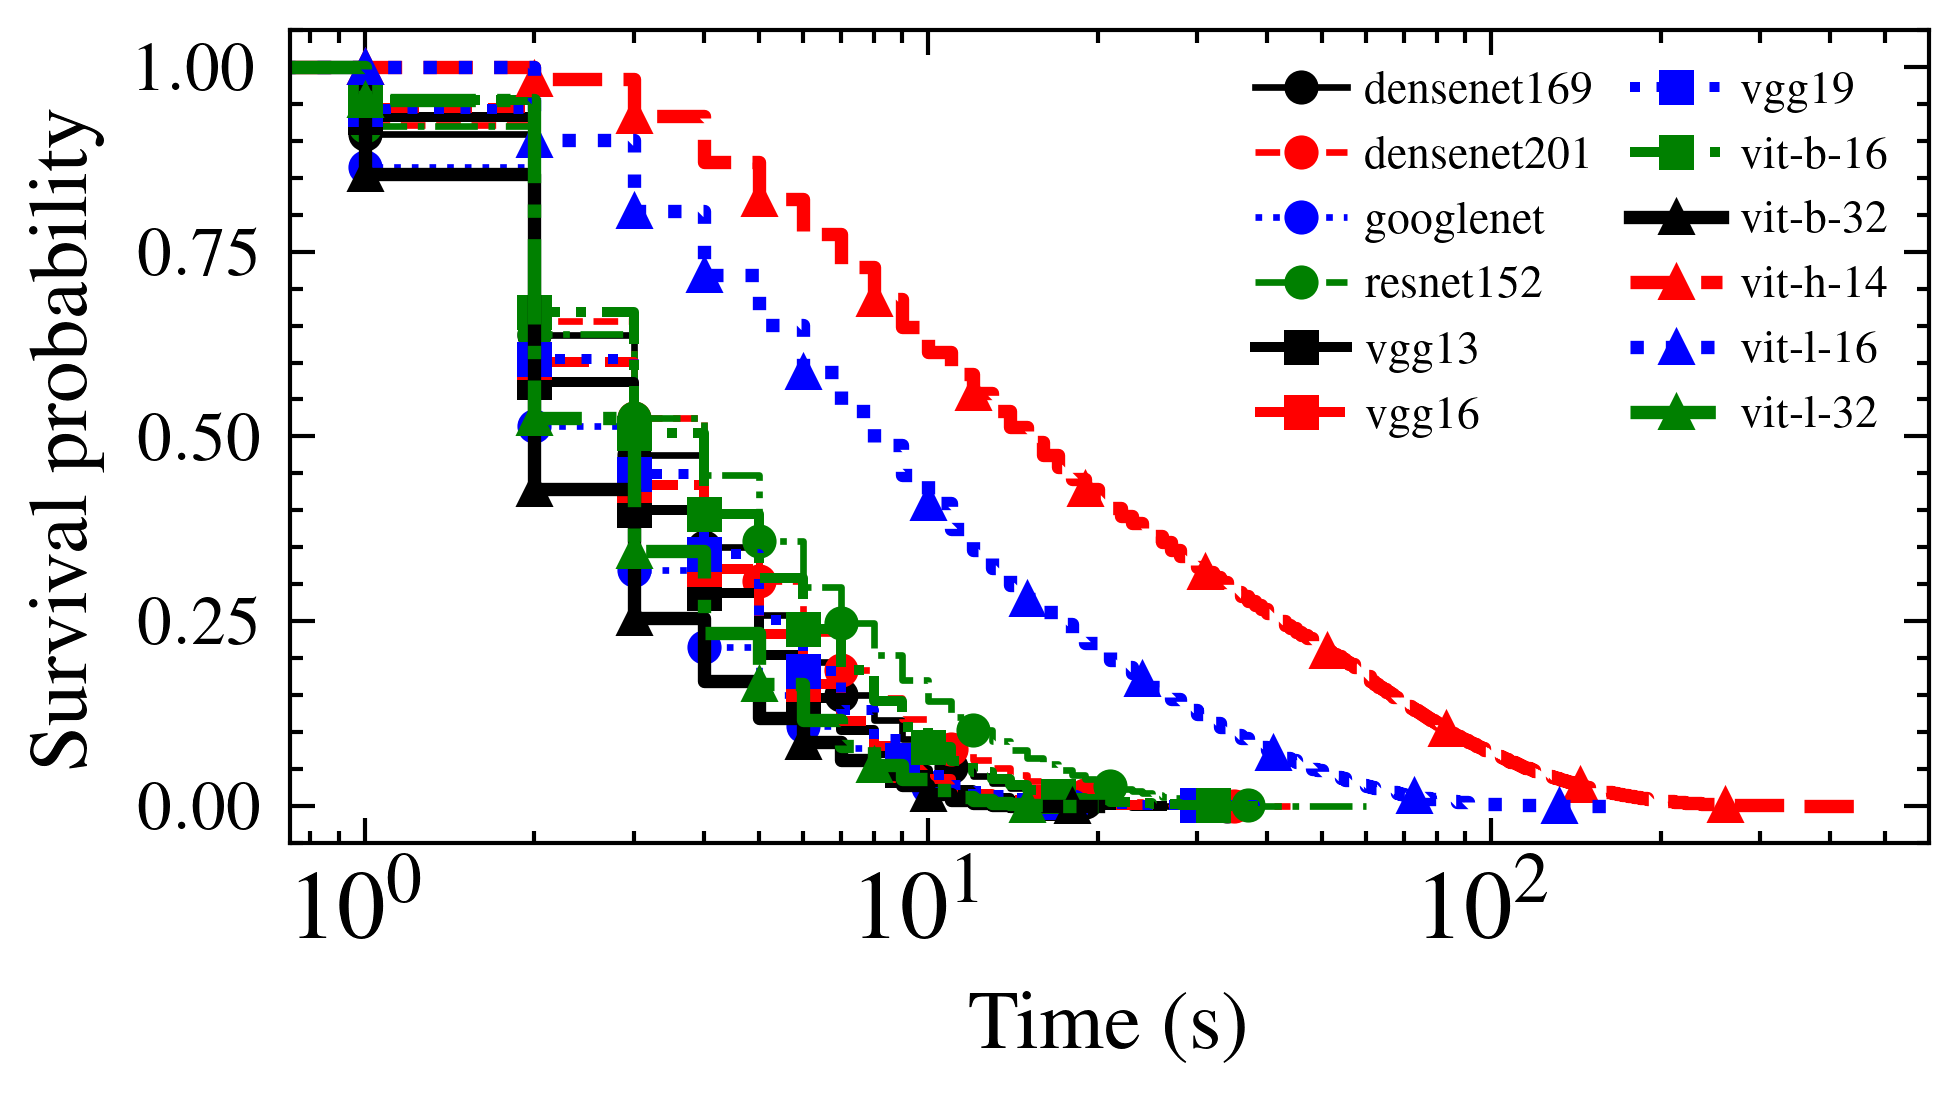

Upload — Empirical KM survival


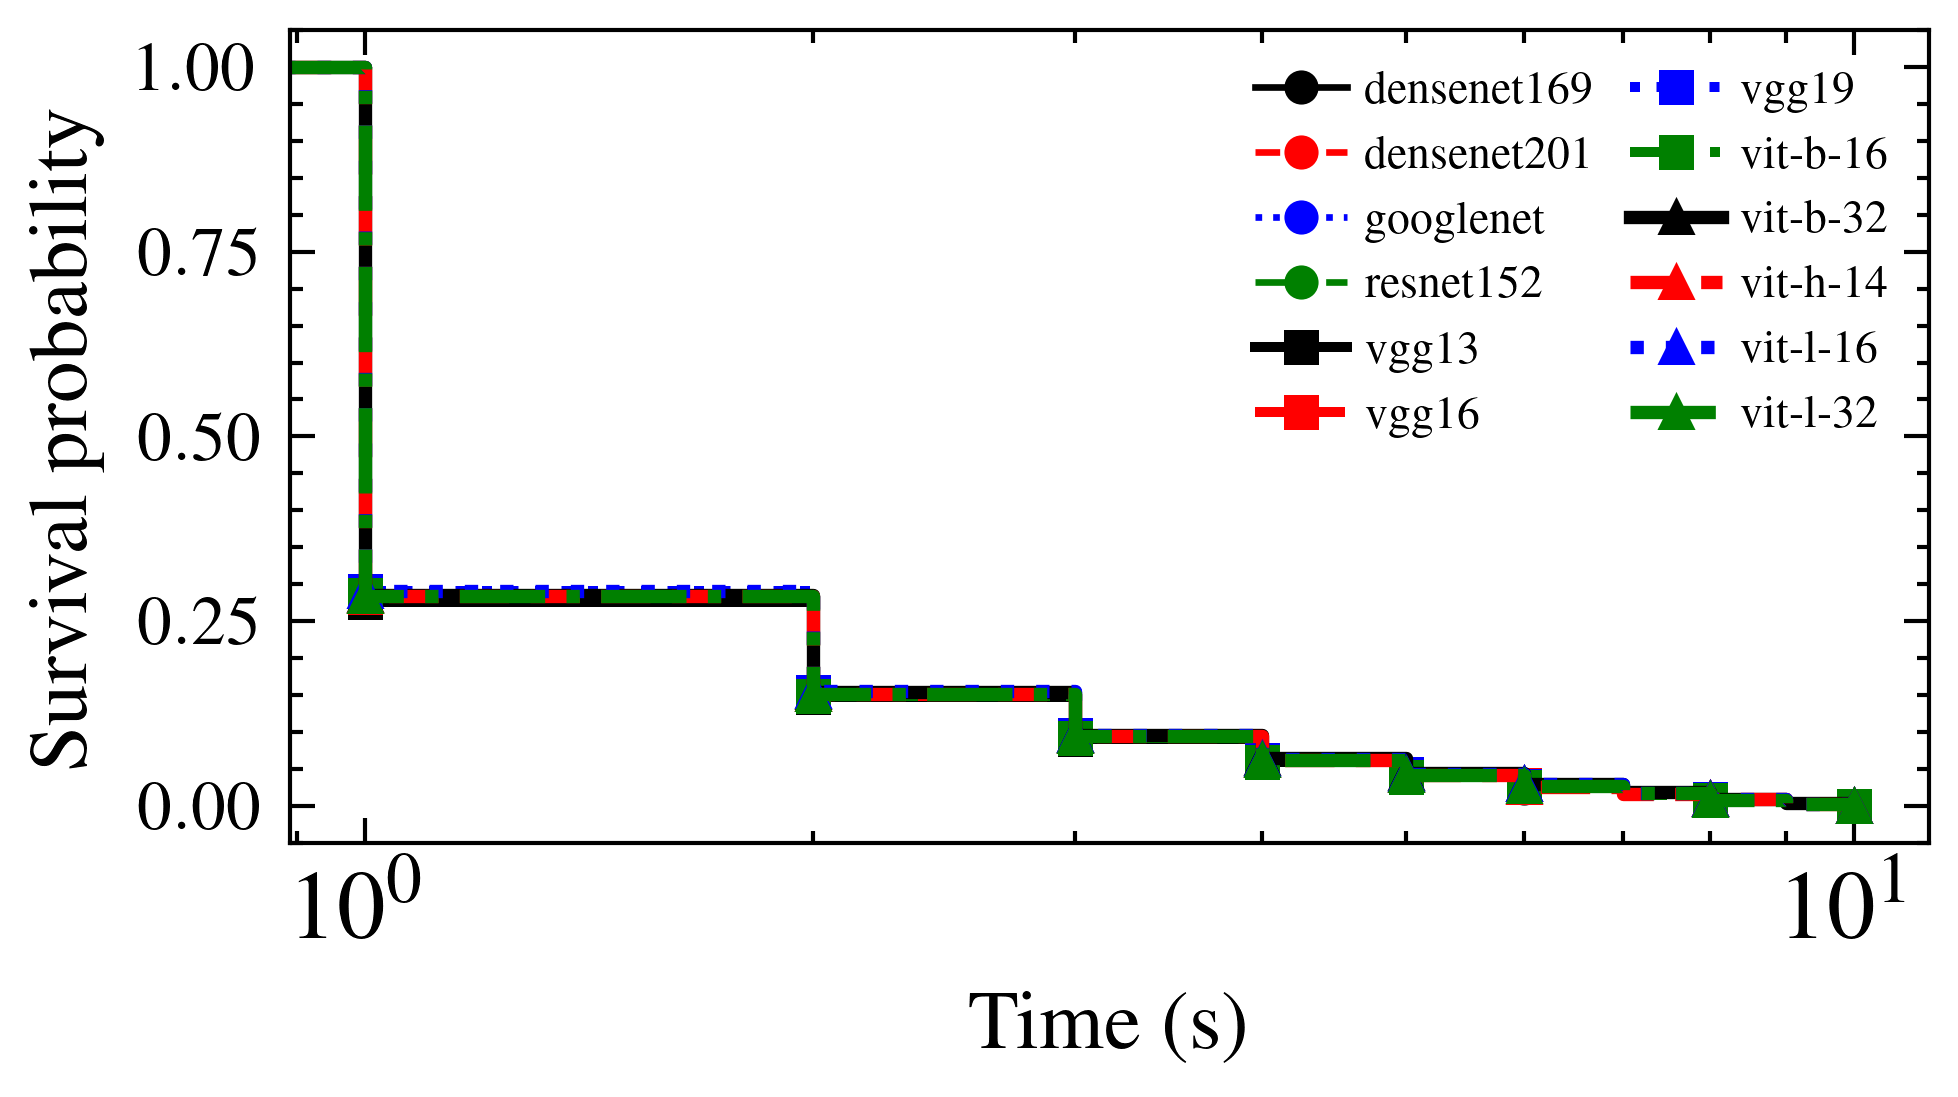

Upload — Model-predicted survival


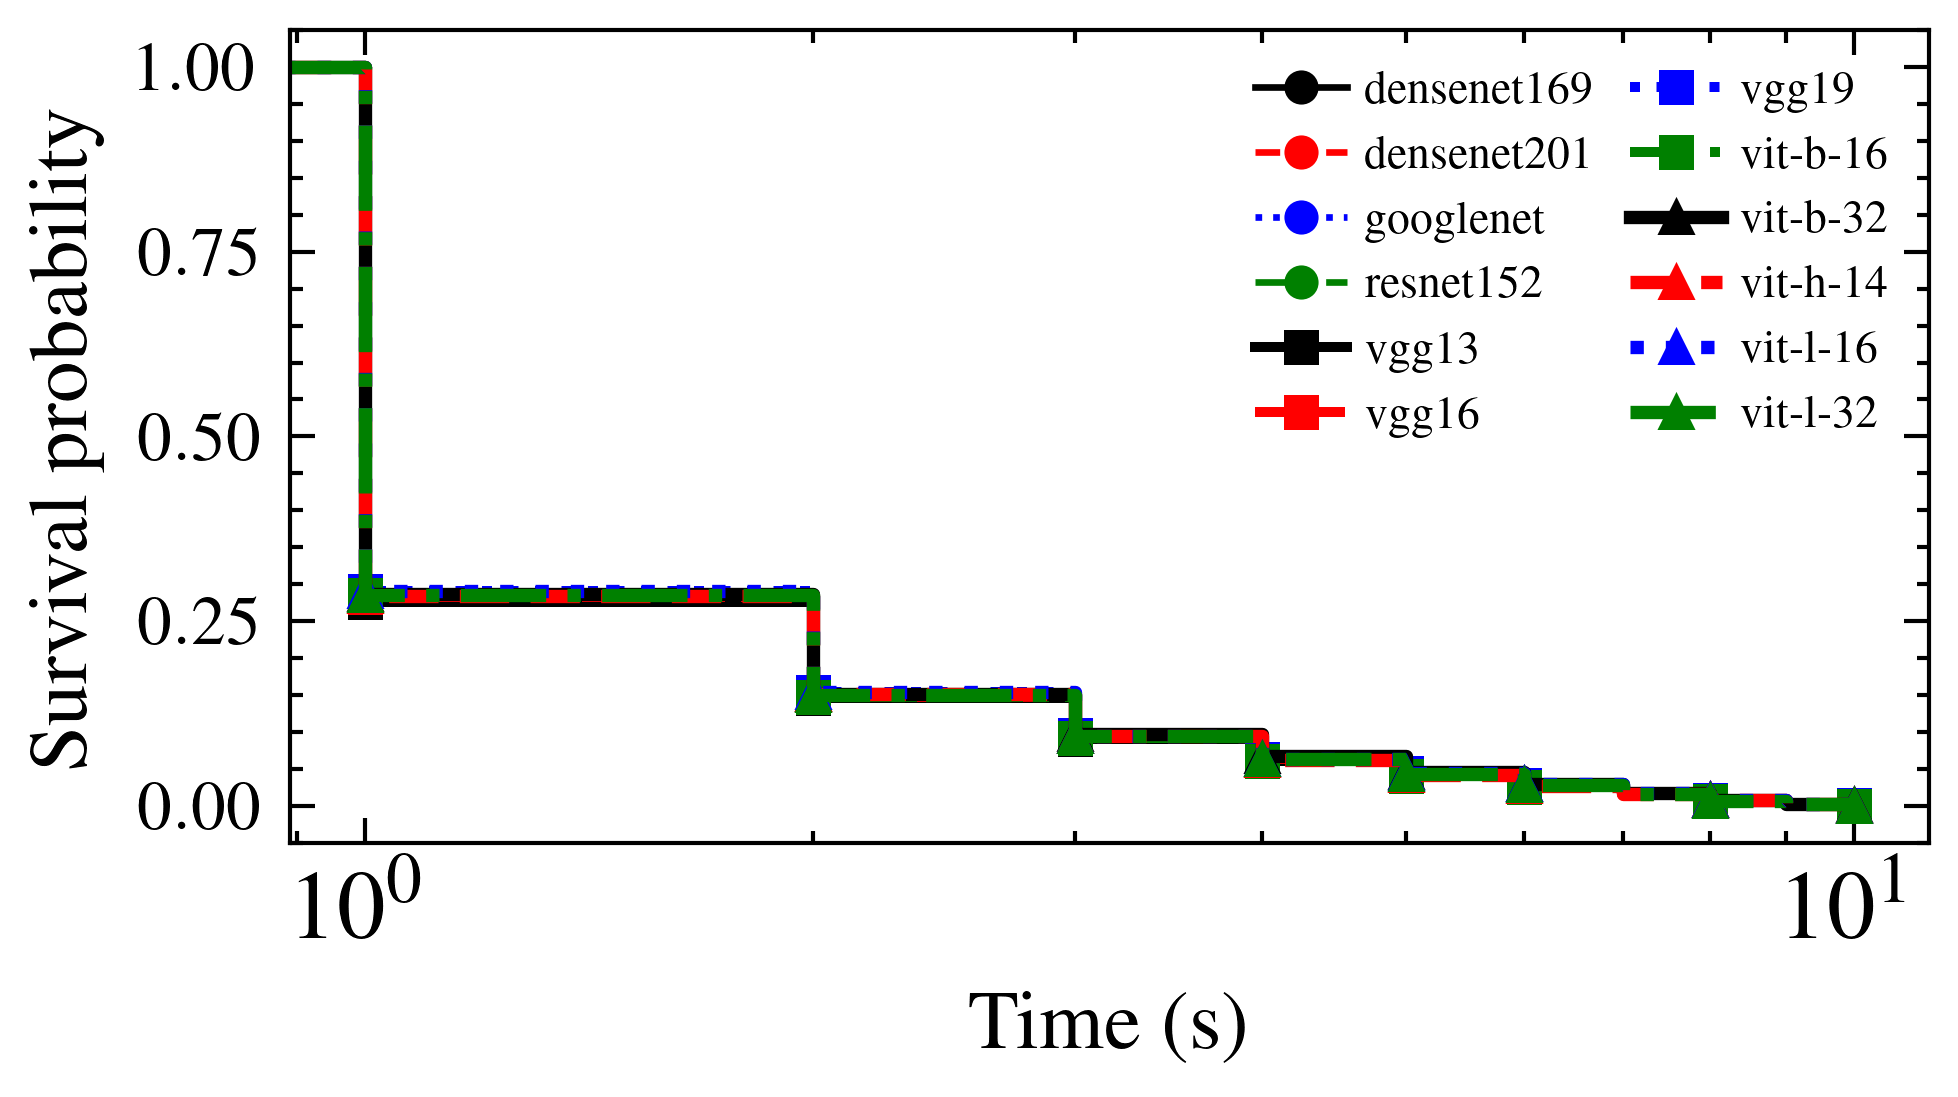

In [7]:
for stage_name, paths in STAGES.items():
    df = pd.read_csv(paths["data_path"])
    model = TaskCompletionModel.load(paths["model_path"])

    task_df, strata_labels, kmfs = empirical_km_curves(df, CONF_COLUMNS, STRATIFICATION_COLS)
    plot_empirical_km(strata_labels, kmfs, f"{stage_name.capitalize()} — Empirical KM survival",
                       f"km_empirical_{stage_name}.pdf")

    curves = model_predicted_survival_curves(df, task_df, model, CONF_COLUMNS)
    plot_model_curves(strata_labels, curves, f"{stage_name.capitalize()} — Model-predicted survival",
                       f"km_model_{stage_name}.pdf", show_ylabel=True)